# Главы 12–13. Ансамбли (`VotingEnsemble`) и стекинг (`StackingEnsemble`)

# 1. Теория

## 1.1 Идея ансамбля

### Что такое ансамбль и зачем он нужен
До сих пор мы выбирали **одну** лучшую модель. Но «лучшая» обычно лучшая только в среднем: на одних окнах выигрывает одна модель, на других — другая, и заранее не угадать, какая сработает в следующие две недели.

**Ансамбль** не выбирает. Несколько конвейеров прогнозируют одно и то же, а итоговый прогноз собирается из их прогнозов. Идея та же, что у «мнения нескольких экспертов»: каждый ошибается по-своему, а вместе — реже.

### Три вида ансамблей в ETNA
Ансамбли различаются тем, **как** они собирают прогнозы базовых моделей в один:
- `VotingEnsemble` — взвешенное среднее прогнозов (спросить всех и усреднить). **Смешивает** прогнозы на каждую дату.
- `StackingEnsemble` — веса подбирает отдельная модель — метамодель (научиться, кому сколько верить).  **Смешивает** прогнозы на каждую дату.
- `DirectEnsemble` — каждый кусок горизонта берёт у своей модели (ближние дни — одному, дальние — другому). **Склеивает** прогнозы. На каждую дату прогноз даёт ровно одна модель

### `VotingEnsemble`: усреднение

**Как работает.** Каждая модель даёт свой прогноз, итоговый прогноз — их среднее. Можно задать веса: например, «лучшей модели — вдвое больше голоса». По умолчанию веса равные — тогда это обычное среднее.

**Почему среднее бывает точнее лучшей модели?** Ошибки разных моделей частично **гасят друг друга**. Пример: в какой-то день было 300 заказов.

| случай | модель A | модель B | среднее | что произошло |
|---|---|---|---|---|
| ошибаются **по-разному** | 320 (+20) | 290 (−10) | **305** (+5) | ошибки погасили друг друга — среднее точнее обеих моделей |
| ошибаются **одинаково** | 320 (+20) | 315 (+15) | 317.5 (+17.5) | обе завысили — гасить нечего, среднее посередине между ними |
| одна модель **заметно слабее** | 305 (+5) | 340 (+40) | 322.5 (+22.5) | слабая модель «перетянула» среднее — оно хуже сильной модели |

Отсюда два правила:
- **брать модели, которые ошибаются по-разному** — разного устройства, а не несколько вариантов одной;
- **брать модели примерно одной силы** — слабая модель в паре с сильной обычно только мешает.

**Плюсы:** просто и прозрачно; нечего переобучать — равные веса не зависят от данных; дёшево: каждая модель обучается один раз.

**Минусы:** равные веса не учитывают, что одна модель сильнее; слабая модель тянет среднее вниз; общее смещение моделей (если все завышают) не убирает. Подбирать веса можно вручную или `weights="auto"`.

### `StackingEnsemble`: веса подбирает метамодель

**Как работает.** Веса задаём не мы — их подбирает **метамодель**: обычная регрессия, которая смотрит на прошлые прогнозы базовых моделей и на факт и учится, кому сколько верить. По умолчанию в ETNA это линейная регрессия `LinearRegression(positive=True)` — веса не могут быть отрицательными.

**Пример.** Две модели, A и B, и их прогнозы на несколько прошлых дней:

| день | прогноз A | прогноз B | факт |
|---|---|---|---|
| 1 | 300 | 280 | 295 |
| 2 | 320 | 340 | 326 |
| 3 | 250 | 270 | 256 |
| 4 | 310 | 290 | 304 |

Факт каждый раз ближе к A, чем к B. Метамодель это замечает и находит правило: **прогноз ≈ 0.7 × A + 0.3 × B**. Модель A получила больший вес, потому что на прошлых днях она была точнее, — сами мы ничего не задавали.

У метамодели есть ещё две свободы, которых нет у простого среднего:
- **веса не обязаны давать в сумме 1.** Например, 0.65 × A + 0.3 × B — в сумме 0.95: такая метамодель «прижимает» прогноз на 5% вниз, если модели в прошлом завышали;
- **свободный член — добавка ко всем прогнозам**, например «+5 заказов». Он **один на все сегменты**: +5 заказов для юнита на 300 заказов в день почти незаметны, а для юнита на 30 — это +17%.

**Откуда метамодель берёт прошлые прогнозы.** Брать прогнозы на те дни, на которых базовые модели сами учились, нельзя: эти дни модели уже «видели», и там они выглядят точнее, чем будут на будущем. Как экзамен по вопросам, которые разбирали на уроке.

Поэтому ETNA устраивает **внутренний backtest** на конце train: прячет от базовых моделей последние недели и просит их честно спрогнозировать эти недели вперёд.

```
train:  [================================|окно 1|окно 2|окно 3]
         базовые модели учатся тут        честные прогнозы → таблица для метамодели
```

При `n_folds=3` и `horizon=14` это последние 42 дня train: 42 строки таблицы на сегмент (на 10 юнитах — 420 строк). Метамодель учится на них, а потом базовые модели переобучаются на всём train — уже для настоящего прогноза.

- **Плюсы:** веса подбираются по данным — сильная модель автоматически получает больший вес; метамодели можно дать и другие признаки (например, день недели), и тогда она может научиться «когда кому верить».
- **Минусы:**
  - **метамодели нужны данные:** внутренний backtest откусывает конец train, на короткой истории строк мало, и веса шумят;
  - **может переобучиться:** подогнать веса под последние недели train, которые не повторятся;
  - **общий свободный член портит мелкие сегменты,** если сегменты разного масштаба;
  - **дорого:** каждая базовая модель обучается несколько раз — при `n_folds=3` четыре раза (три окна + финальное обучение).

### `DirectEnsemble`: склейка по горизонту

**Как работает.** Не смешивает прогнозы, а **делит горизонт между моделями**: ближние дни прогнозирует одна модель, дальние — другая. На каждую дату прогноз даёт ровно одна модель.

**Зачем это нужно.** Вспомним прямую стратегию: лаги должны быть не короче горизонта, иначе для дальних дат их значений ещё нет. Модель на 14 дней вперёд вынуждена брать лаги от 14 — **даже для завтрашнего дня**, хотя для него есть данные посвежее. `DirectEnsemble` решает это так: для ближних дней — отдельная модель с коротким горизонтом и свежими лагами.

**Пример.** Сегодня 17 августа, прогнозируем 18–31 августа. Два конвейера:
- **A** — горизонт 7 дней, лаги от 7;
- **B** — горизонт 14 дней, лаги от 14.

| прогнозируем | кто прогнозирует | самые свежие данные у модели |
|---|---|---|
| 18 августа (1-й день) | A | 11 августа — неделю назад |
| 24 августа (7-й день) | A | 17 августа — сегодня |
| 25 августа (8-й день) | B | 11 августа |
| 31 августа (14-й день) | B | 17 августа — сегодня |

Одна модель B на все 14 дней прогнозировала бы 18 августа по данным за 4 августа — двухнедельной давности. В ансамбле первую неделю берёт A и опирается на данные на неделю свежее.

Правило выбора у ETNA: на каждую дату берётся модель с **самым коротким горизонтом, который до этой даты достаёт**. Дни 1–7 достают обе модели — берётся A (горизонт короче), дни 8–14 достаёт только B.

- **Плюсы:** ближние дни прогнозируются по более свежим данным; каждая модель — «специалист» по своему куску горизонта.
- **Минусы:**
  - **не усредняет** — ошибки моделей не гасят друг друга, как в `VotingEnsemble`;
  - **на стыке кусков прогноз может «скакнуть»:** 24 августа — прогноз модели A, 25-го — уже модели B;
  - **моделей нужно столько, сколько кусков горизонта,** и у каждой должен быть свой горизонт;
  - **полезен в основном для моделей на лагах** (CatBoost и т. п.). Моделям вроде `HoltWintersModel` или `ProphetModel` свежесть лагов не важна — им этот ансамбль ничего не даёт.

В этой тетради `DirectEnsemble` не используем: работаем с ансамблями, которые смешивают прогнозы.

## 1.2 Параметры и реализация

Исходники `etna/ensembles/voting_ensemble.py` и `etna/ensembles/stacking_ensemble.py`:

```python
class VotingEnsemble(EnsembleMixin, SaveEnsembleMixin, BasePipeline):
    def __init__(
        self,
        pipelines: List[BasePipeline],
        weights: Optional[Union[List[float], Literal["auto"]]] = None,
        regressor: Optional[TreeBasedRegressor] = None,
        n_folds: int = 3,
        n_jobs: int = 1,
        joblib_params: Optional[Dict[str, Any]] = None,
    ):
        ...
        self.regressor = RandomForestRegressor(n_estimators=5) if regressor is None else regressor
        ...
        if joblib_params is None:
            self.joblib_params = dict(verbose=11, backend="multiprocessing", mmap_mode="c")

class StackingEnsemble(EnsembleMixin, SaveEnsembleMixin, BasePipeline):
    def __init__(
        self,
        pipelines: List[BasePipeline],
        final_model: Optional[RegressorMixin] = None,
        n_folds: int = 3,
        features_to_use: Union[None, Literal["all"], List[str]] = None,
        n_jobs: int = 1,
        joblib_params: Optional[Dict[str, Any]] = None,
    ):
        ...
        self.final_model = LinearRegression(positive=True) if final_model is None else final_model
```

**Параметры `VotingEnsemble`:**
- `pipelines` — список конвейеров (минимум 2, горизонт у всех одинаковый). У каждого свои модель и трансформы.
- `weights` — веса:
  - `None` — равные;
  - список чисел, например `[2, 1]` — ETNA сама нормирует их до суммы 1;
  - `"auto"` — веса = важности признаков модели `regressor`, обученной на внутреннем backtest (прогнозы моделей → факт).
- `regressor` — модель для `weights="auto"`, нужен атрибут `feature_importances_`. По умолчанию `RandomForestRegressor(n_estimators=5)` — **без `random_state`**.
- `n_folds` — число окон внутреннего backtest. Используется только при `weights="auto"`.
- `n_jobs`, `joblib_params` — параллельность. По умолчанию `verbose=11` — очень шумный лог.

**Параметры `StackingEnsemble`:**
- `pipelines` — как у `VotingEnsemble`.
- `final_model` — метамодель, любая регрессия sklearn с `fit` / `predict`. По умолчанию `LinearRegression(positive=True)`: коэффициенты неотрицательные, свободный член есть.
- `n_folds` *(3)* — число окон внутреннего backtest — сколько строк будет у метамодели.
- `features_to_use` — что ещё, кроме прогнозов базовых моделей, дать метамодели:
  - `None` — только прогнозы;
  - список имён колонок, например `["flag_day_number_in_week"]` — прогнозы плюс эти признаки (они должны создаваться трансформами базовых конвейеров);
  - `"all"` — все признаки из всех конвейеров.

**В отличие от `Pipeline`:**
- вместо `model` + `transforms` — список готовых конвейеров;
- интерфейс тот же: `fit`, `forecast`, `backtest`, `get_historical_forecasts`. Ансамбль сравнивают с одиночными моделями тем же `backtest`;
- интервалов прогноза нет (`NotImplementedError`), `return_components=True` тоже не поддерживается;
- `StackingEnsemble.fit` дороже `Pipeline.fit`: каждая базовая модель обучается $\large n\_folds + 1$ раз, а внутри `backtest` — ещё и на каждом внешнем фолде.

## 1.3 Особенности

- **Метамодель одна на все сегменты.** Строки всех рядов складываются в одну таблицу (`_make_features`: `pd.concat` по сегментам), и `LinearRegression` подбирает **общие** коэффициенты и **общий** свободный член $\large b$. На юнитах разного масштаба (30 и 300 заказов в день) сдвиг $\large b$ одинаковый для всех — на маленьких юнитах он может заметно испортить прогноз.
- **Метамодели мало данных.** При `n_folds=3` и `horizon=14` — 42 строки на сегмент, только с последних 42 дней train. Коэффициенты подбираются по короткому отрезку и могут шуметь от фолда к фолду.
- **Внутренний backtest требует истории.** Внутри внешнего `backtest(n_folds=5)` первый фолд учится на `153 − 5·14 = 83` днях, а внутренний backtest стекинга отрезает от них ещё `n_folds·14`. ETNA проверяет, что в ряде есть хотя бы `n_folds·horizon` точек, иначе `ValueError: … should contain at least …`. CatBoost с длинными лагами падает раньше: на коротком train после выброса строк с `NaN` в лагах ничего не остаётся — `CatBoostError: Labels variable is empty`. Поэтому в этой тетради у CatBoost лаги `[14, 21, 28]`, а не до 56, как в тетради про `CatBoostPerSegmentModel`.
- **`weights="auto"` случайны.** Случайный лес из 5 деревьев без `random_state`: веса меняются от запуска к запуску. Кроме того, важность признака — это «насколько признак полезен лесу», а не «с каким весом его усреднять». Если нужны воспроизводимые веса — передай `regressor=RandomForestRegressor(n_estimators=..., random_state=42)` или задай веса списком.
- **CatBoost в ансамбле тоже случаен — даже с `random_seed`.** Внутри одного запуска ядра результат стабилен, но после перезапуска ядра CatBoost может дать другой SMAPE (±0.1–0.2): ETNA хранит список признаков-регрессоров во множестве (`set`), а порядок элементов `set` в Python меняется от запуска к запуску — и CatBoost получает колонки в другом порядке. Поэтому разница между ансамблями с CatBoost в 0.1 SMAPE — это шум.
- **Шумный лог.** `joblib_params=dict(verbose=0)` в конструкторе ансамбля и в `backtest` помогает не полностью: в ETNA 3.0.0 `VotingEnsemble.forecast` жёстко задаёт `verbose=11`, а внутренний backtest ансамблей вызывается без наших параметров. Поэтому в практике вызовы оборачиваем в `quiet()` — он перенаправляет этот лог в никуда.
- **Расхождения с пособием** (там ETNA 2.x):
  - `features_to_use='None'` строкой в ETNA 3.0.0 — «неверный формат»: ETNA выдаёт предупреждение и использует только прогнозы, то есть то же, что `None`. Пишем `None` без кавычек;
  - `backtest` возвращает словарь: `result["metrics"]`, `result["forecasts"]`, а не кортеж `(metrics, forecasts, fold_info)`.
- **Сравнение нескольких моделей** — это просто цикл по конвейерам с `backtest` и таблица метрик: отдельного класса для этого в ETNA нет. Логировать такие сравнения удобнее в MLflow, как в прошлых тетрадях.
- **Дальше:** собственные классы моделей — как обернуть в ETNA модель, которой в библиотеке нет.

# 2. Данные

Те же файлы, что и в предыдущих тетрадях (`local/data/`, в `.gitignore`):
- `units.csv` — 10 юнитов;
- `facts-by-date.csv` — дневные факты.

**В этой тетради сразу берём все 10 юнитов**, без 2-юнитовой разминки. Выигрыш ансамбля — доли SMAPE. На 2 юнитах его не отличить от шума, на 10 — уже видно.

Период и сплит — как в прошлых тетрадях: с 2026-04-01, test — последние 14 дней (2026-08-18 … 2026-08-31). Основное сравнение — по **backtest** (5 фолдов, `expand`): одно окно holdout для разницы в 0.5 SMAPE ненадёжно (тетрадь про `ProphetModel`).

В этой главе не сравниваем с продовым прогнозом (`forecasts-by-date.csv`) — это отдельная тема.

In [1]:
import logging
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

from etna.datasets import TSDataset
from etna.models import (
    NaiveModel,
    SeasonalMovingAverageModel,
    HoltWintersModel,
    ProphetModel,
    CatBoostPerSegmentModel,
)
from etna.transforms import LagTransform
from etna.pipeline import Pipeline
from etna.ensembles import VotingEnsemble, StackingEnsemble
from etna.metrics import SMAPE, WAPE, MAPE, MAE
from etna.analysis import plot_forecast, plot_backtest

from src.custom_logger import log_to_mlflow
from src.prod_metrics import bias, pooled

logging.getLogger("cmdstanpy").disabled = True
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = "../../local/data"
HORIZON = 14
RANDOM_SEED = 42
BACKTEST_N_FOLDS = 5
BACKTEST_MODE = "expand"
JOBLIB_PARAMS = dict(verbose=0)  # глушим лог joblib и в ансамблях, и в backtest

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 3. Практика

Синтетику в этот раз пропускаем: суть ансамбля — в том, как по-разному ошибаются **настоящие** модели на **настоящих** рядах, а синтетика с одним шумом этого не покажет.

План: собираем 5 знакомых моделей и смотрим, насколько похоже они ошибаются:
 - Задание 1 - усредняем их через `VotingEnsemble`
 - Задание 2 - даём весам подобраться самим через `StackingEnsemble`

## Задание 1. Базовые модели и их ошибки

Готовим «сырьё» для ансамблей: 5 одиночных моделей, их backtest и корреляцию их ошибок.

### Шаг 1.1. Загрузка и сплит

1. Прочитай `facts-by-date.csv` и `units.csv`, оставь период с 2026-04-01, все 10 юнитов.
2. Собери `TSDataset` (дневная частота, `segment` = `MaskedUnitId`) и раздели на train / test (последние `HORIZON` дней).

In [2]:
units_df = (
    pd.read_csv(f"{DATA_DIR}/units.csv")
    .rename(columns={
        "MaskedUnitId": "segment",
        "UnitSize": "unit_size",
        "PickReason": "pick_reason",
        "TotalOrders": "total_orders",
    })
    [["segment", "unit_size", "pick_reason", "total_orders"]]
)

orders_df = (
    pd.read_csv(f"{DATA_DIR}/facts-by-date.csv")
    .rename(columns={
        "CalendarDate": "timestamp",
        "MaskedUnitId": "segment",
        "Fact": "target",
    })
    [["timestamp", "segment", "target"]]
)
orders_df = orders_df[orders_df["timestamp"] >= "2026-04-01"]  # стандартный период, все 10 юнитов

all_ts = TSDataset(orders_df, freq="D")
train_ts, test_ts = all_ts.train_test_split(test_size=HORIZON)

print(f"train: {train_ts.timestamps.min().date()} … {train_ts.timestamps.max().date()} ({len(train_ts.timestamps)} дней)")
print(f"test:  {test_ts.timestamps.min().date()} … {test_ts.timestamps.max().date()} ({len(test_ts.timestamps)} дней)")
print(f"юнитов: {len(all_ts.segments)}")
units_df

train: 2026-04-01 … 2026-08-17 (139 дней)
test:  2026-08-18 … 2026-08-31 (14 дней)
юнитов: 10


,segment,unit_size,pick_reason,total_orders
0,a6dffdeb,10+,busier (p75),29099
1,70650540,10+,typical (p25),25437
2,3bfb39ef,3–5,busier (p75),9530
3,9bb64107,3–5,typical (p25),7888
4,155082de,5–7,busier (p75),13509
5,733e17e8,5–7,typical (p25),12470
6,aa88e1ec,7–10,busier (p75),19363
7,d3319417,7–10,typical (p25),17464
8,8a399130,<3,busier (p75),5646
9,a5cd0472,<3,typical (p25),4051


#### Выводы

- Train — 2026-04-01 … 2026-08-17 (139 дней), test — 2026-08-18 … 2026-08-31 (14 дней), 10 юнитов. Период и сплит те же, что в прошлых тетрадях, поэтому результаты сравнимы напрямую.
- Юниты очень разные по размеру: от ~45 до ~320 заказов в день. Это пригодится в Задании 3.

### Шаг 1.2. Пять базовых конвейеров: backtest

Сделай функцию `make_base_pipelines()`, которая каждый раз создаёт **новые** конвейеры (пригодится во всех следующих шагах: ансамбль обучает конвейеры, которые ему передали, поэтому один и тот же экземпляр в два ансамбля не отдаём):
- `naive_7` — `NaiveModel(lag=7)`;
- `sma` — `SeasonalMovingAverageModel(window=4, seasonality=7)`;
- `holt_winters` — `HoltWintersModel(trend=None, seasonal="add", seasonal_periods=7)`;
- `prophet` — `ProphetModel(growth="flat")`;
- `catboost` — `CatBoostPerSegmentModel(random_seed=RANDOM_SEED)` + `LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")` (почему лаги короче, чем в тетради про CatBoost, — раздел 1.3).

Прогони каждый через `backtest` (`n_folds=BACKTEST_N_FOLDS`, `mode=BACKTEST_MODE`, `joblib_params=JOBLIB_PARAMS`). Сохрани результаты `backtest` целиком — прогнозы понадобятся в шагах 1.3 и 2.1.

Собери таблицу: строки — модели, колонки — SMAPE по фолдам (среднее по 10 юнитам), среднее по фолдам и худший фолд.

- Какая модель лучшая по среднему? А по худшему фолду?
- Одна ли модель лучшая на всех фолдах?

In [3]:
import io
from contextlib import redirect_stderr


def quiet():
    """Глушит лог joblib: ETNA 3.0.0 печатает его внутри ансамблей, даже если передать verbose=0."""
    return redirect_stderr(io.StringIO())


def make_base_pipelines() -> dict:
    """Пять базовых конвейеров. Создаёт их ЗАНОВО при каждом вызове: один экземпляр в два ансамбля не отдаём."""
    return {
        "naive_7": Pipeline(NaiveModel(lag=7), horizon=HORIZON),
        "sma": Pipeline(SeasonalMovingAverageModel(window=4, seasonality=7), horizon=HORIZON),
        "holt_winters": Pipeline(HoltWintersModel(trend=None, seasonal="add", seasonal_periods=7), horizon=HORIZON),
        "prophet": Pipeline(ProphetModel(growth="flat"), horizon=HORIZON),
        "catboost": Pipeline(
            CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
            transforms=[LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")],
            horizon=HORIZON,
        ),
    }


def run_backtest(pipeline) -> dict:
    """Backtest с общими настройками тетради: 5 фолдов × 14 дней, expand."""
    with quiet():
        return pipeline.backtest(
            ts=all_ts,
            metrics=[SMAPE()],
            n_folds=BACKTEST_N_FOLDS,
            mode=BACKTEST_MODE,
            joblib_params=JOBLIB_PARAMS,
        )


backtest_results = {}  # имя → результат backtest целиком (metrics, forecasts, fold_info, pipelines)
for name, pipeline in make_base_pipelines().items():
    started = time.perf_counter()
    backtest_results[name] = run_backtest(pipeline)
    print(f"{name:<13} {time.perf_counter() - started:5.1f} с")

naive_7         0.0 с
sma             0.0 с
holt_winters    0.6 с
prophet         1.8 с
catboost        6.3 с


In [4]:
def folds_table(names: list) -> pd.DataFrame:
    """Строки — модели, колонки — SMAPE по фолдам (среднее по 10 юнитам), среднее по фолдам и худший фолд."""
    table = pd.DataFrame({
        name: backtest_results[name]["metrics"].groupby("fold_number")["SMAPE"].mean()
        for name in names
    }).T
    table.columns = [f"fold_{fold}" for fold in table.columns]
    table["mean"] = table.mean(axis=1)
    table["worst_fold"] = table[[c for c in table.columns if c.startswith("fold_")]].max(axis=1)
    return table.sort_values("mean")


base_names = list(make_base_pipelines())
base_table = folds_table(base_names)
print("лучшая модель на каждом фолде:", base_table.filter(like="fold_").idxmin().to_dict())
base_table.round(2)

лучшая модель на каждом фолде: {'fold_0': 'holt_winters', 'fold_1': 'sma', 'fold_2': 'holt_winters', 'fold_3': 'holt_winters', 'fold_4': 'holt_winters'}


,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
holt_winters,14.58,12.97,12.45,11.16,11.36,12.50,14.58
prophet,14.65,11.72,12.94,11.29,12.46,12.61,14.65
sma,14.99,11.00,14.36,11.33,12.15,12.77,14.99
naive_7,15.91,18.18,13.42,11.63,11.64,14.15,18.18
catboost,17.17,13.23,16.12,13.21,14.21,14.79,17.17


#### Выводы

> У CatBoost числа могут немного отличаться от запуска к запуску. Остальные модели детерминированы.

| модель | SMAPE, среднее по 5 фолдам | худший фолд |
|---|---|---|
| `holt_winters` | **12.50** | **14.58** |
| `prophet` | 12.61 | 14.65 |
| `sma` | 12.77 | 14.99 |
| `naive_7` | 14.15 | 18.18 |
| `catboost` | ~14.9 | ~17.3 |

- **Лучшая по среднему и по худшему фолду — `holt_winters`.** Но отрыв от `prophet` и `sma` маленький — 0.1–0.3 SMAPE. Три модели примерно одной силы.
- **Одной лучшей модели на всех фолдах нет.** `holt_winters` выигрывает 4 фолда из 5, а на фолде 1 лучше всех `sma` (11.00 против 12.97). Каждая модель где-то сильнее остальных — это и есть сырьё для ансамбля.
- **Фолд 0 трудный для всех** (14.6–17.3): дело в самом окне, а не в моделях.
- `naive_7` и `catboost` заметно слабее. `catboost` здесь с короткими лагами (14–28) и на короткой истории — как и в тетради про CatBoost, он проигрывает простым моделям.

### Шаг 1.3. Насколько похоже ошибаются модели

Из прогнозов backtest шага 1.2 собери таблицу ошибок: строка — (дата, юнит), колонка — модель, значение — `прогноз − факт`. Посчитай:
- матрицу корреляций ошибок (`.corr()`);
- средний bias каждой модели (`.mean()`): кто систематически завышает, кто занижает.

- Какая пара моделей ошибается похоже, а какая — по-разному?
- По таблице из раздела 1.1: какая пара, скорее всего, даст больший выигрыш от усреднения? Запиши гипотезу до шага 2.1.

In [5]:
# Таблица ошибок из прогнозов backtest: строка — (фолд, дата, юнит), колонка — модель, значение — прогноз − факт
fact_long = all_ts.to_pandas(flatten=True)[["timestamp", "segment", "target"]].rename(columns={"target": "fact"})


def backtest_forecasts_long(result: dict) -> pd.DataFrame:
    """Прогнозы всех фолдов backtest в одну длинную таблицу: fold_number, timestamp, segment, forecast."""
    return pd.concat([
        forecast_ts.to_pandas(flatten=True)[["timestamp", "segment", "target"]]
        .rename(columns={"target": "forecast"})
        .assign(fold_number=fold)
        for fold, forecast_ts in enumerate(result["forecasts"])
    ])


forecasts_long = {name: backtest_forecasts_long(backtest_results[name]) for name in base_names}

errors_df = pd.DataFrame({
    name: (
        forecast_df.merge(fact_long, on=["timestamp", "segment"])
        .set_index(["fold_number", "timestamp", "segment"])
        .eval("forecast - fact")
    )
    for name, forecast_df in forecasts_long.items()
})
print(f"строк: {len(errors_df)} = 5 фолдов × 14 дней × 10 юнитов")
errors_df.head()

строк: 700 = 5 фолдов × 14 дней × 10 юнитов


naive_7    sma  holt_winters    prophet  \
fold_number timestamp  segment                                             
0           2026-06-23 155082de     34.0   7.50     12.726862 -10.818829   
            2026-06-24 155082de      8.0   8.25     13.510925 -10.750592   
            2026-06-25 155082de     11.0   2.50      9.064646 -14.750642   
            2026-06-26 155082de     26.0  12.75     29.535055   6.165833   
            2026-06-27 155082de     29.0   9.75     24.255291   1.332556   

                                  catboost  
fold_number timestamp  segment              
0           2026-06-23 155082de  20.975241  
            2026-06-24 155082de  11.629330  
            2026-06-25 155082de -11.384069  
            2026-06-26 155082de -27.468203  
            2026-06-27 155082de  30.027967

In [6]:
# Насколько похоже ошибаются модели: корреляция ошибок (1 — ошибаются одинаково, 0 — независимо)
errors_corr = errors_df.corr()
errors_corr.round(2)

,naive_7,sma,holt_winters,prophet,catboost
naive_7,1.00,0.77,0.71,0.58,0.61
sma,0.77,1.00,0.85,0.80,0.83
holt_winters,0.71,0.85,1.00,0.86,0.70
prophet,0.58,0.80,0.86,1.00,0.64
catboost,0.61,0.83,0.70,0.64,1.00


In [7]:
# Bias: средняя ошибка в заказах (> 0 — модель в среднем завышает, < 0 — занижает) и в % от среднего факта
bias_df = pd.DataFrame({
    "bias_orders": errors_df.mean(),
    "bias_pct": errors_df.mean() / fact_long["fact"].mean() * 100,
})
bias_df.round(2)

,bias_orders,bias_pct
naive_7,3.76,2.39
sma,2.41,1.53
holt_winters,3.11,1.97
prophet,1.24,0.79
catboost,4.46,2.83


#### Выводы

**Все модели ошибаются похоже** — корреляция ошибок от 0.58 до 0.86, ни одной пары около нуля. Это естественно: если в какой-то день заказов неожиданно много, ошибаются все модели сразу и в одну сторону.

| пара | корреляция ошибок | как ошибаются |
|---|---|---|
| `holt_winters` + `prophet` | 0.86 | самые похожие |
| `sma` + `holt_winters` | 0.85 | очень похоже |
| `naive_7` + `catboost` | ~0.61 | по-разному |
| `naive_7` + `prophet` | 0.58 | самые разные |

**Bias у всех моделей одного знака:** все немного завышают — от +0.8% (`prophet`) до ~+2.9% (`catboost`). Значит, усреднение смещение не уберёт: если все завышают, среднее тоже завышает. Выигрыш ансамбля может прийти только от того, что гасятся случайные ошибки отдельных дней.

**Гипотеза до шага 2.1**: больше всего от усреднения выиграет самая «непохожая» пара `naive_7` + `prophet`, меньше всего — самая похожая `holt_winters` + `prophet`.

## Задание 2. `VotingEnsemble`: усредняем прогнозы

Используем `make_base_pipelines()` и результаты backtest из Задания 1.

### Шаг 2.1. Среднее руками против `VotingEnsemble`

1. Прямо из прогнозов backtest шага 1.2 (без обучения!) посчитай простое среднее для **каждой пары** моделей и его SMAPE (среднее по юнитам и фолдам). Собери таблицу: пара, корреляция ошибок пары (шаг 1.3), SMAPE лучшей модели пары, SMAPE среднего, выигрыш.
2. Для одной пары прогони `VotingEnsemble(pipelines=[...], joblib_params=JOBLIB_PARAMS).backtest(...)` и проверь, что SMAPE совпадает с ручным средним.

- Подтвердилась ли гипотеза из шага 1.3? Есть ли связь между корреляцией ошибок пары и выигрышем?
- Есть ли пара, где среднее хуже лучшей модели пары? Почему так бывает?

In [27]:
from itertools import combinations


def smape_of_forecast(forecast_df: pd.DataFrame) -> float:
    """SMAPE как в backtest: по каждой паре (юнит, фолд) за 14 дней, потом среднее."""
    df = forecast_df.merge(fact_long, on=["timestamp", "segment"])
    df["smape"] = 200 * (df["forecast"] - df["fact"]).abs() / (df["forecast"].abs() + df["fact"].abs())
    return df.groupby(["segment", "fold_number"])["smape"].mean().mean()


# Проверка: ручная формула даёт то же, что backtest
check_name = "holt_winters"
print(f"ручной SMAPE {check_name}: {smape_of_forecast(forecasts_long[check_name]):.4f}, "
      f"backtest: {backtest_results[check_name]['metrics']['SMAPE'].mean():.4f}")

# Простое среднее каждой пары — прямо из прогнозов backtest, без обучения
pair_rows = []
for first, second in combinations(base_names, 2):
    mean_forecast = forecasts_long[first].copy()
    mean_forecast["forecast"] = (forecasts_long[first]["forecast"].values + forecasts_long[second]["forecast"].values) / 2
    best_single = min(base_table.loc[first, "mean"], base_table.loc[second, "mean"])
    pair_smape = smape_of_forecast(mean_forecast)
    pair_rows.append({
        "pair": f"{first} + {second}",
        "errors_corr": errors_corr.loc[first, second],
        "quality_gap": abs(base_table.loc[first, "mean"] - base_table.loc[second, "mean"]),  # насколько модели пары разные по силе
        "best_single_smape": best_single,
        "pair_mean_smape": pair_smape,
        "gain": best_single - pair_smape,  # > 0 — среднее лучше лучшей модели пары
    })

pairs_df = pd.DataFrame(pair_rows).set_index("pair").sort_values("errors_corr")
pairs_df.round(2)

ручной SMAPE holt_winters: 12.5046, backtest: 12.5046


,errors_corr,quality_gap,best_single_smape,pair_mean_smape,gain
pair,,,,,
naive_7 + prophet,0.58,1.54,12.61,12.00,0.61
naive_7 + catboost,0.61,0.63,14.15,12.96,1.19
prophet + catboost,0.64,2.17,12.61,12.40,0.22
holt_winters + catboost,0.70,2.28,12.50,12.43,0.08
naive_7 + holt_winters,0.71,1.65,12.50,12.56,-0.06
naive_7 + sma,0.77,1.39,12.77,12.75,0.01
sma + prophet,0.80,0.16,12.61,12.06,0.55
sma + catboost,0.83,2.02,12.77,13.14,-0.38
sma + holt_winters,0.85,0.26,12.50,12.06,0.44


In [9]:
# Для одной пары — настоящий VotingEnsemble: SMAPE должен совпасть с ручным средним
base = make_base_pipelines()
backtest_results["vote_hw_prophet"] = run_backtest(
    VotingEnsemble(pipelines=[base["holt_winters"], base["prophet"]], joblib_params=JOBLIB_PARAMS)
)
print(f"VotingEnsemble holt_winters + prophet: {backtest_results['vote_hw_prophet']['metrics']['SMAPE'].mean():.4f}")
print(f"ручное среднее той же пары:            {pairs_df.loc['holt_winters + prophet', 'pair_mean_smape']:.4f}")

VotingEnsemble holt_winters + prophet: 11.9089
ручное среднее той же пары:            11.9089


корреляция выигрыша с каждой из величин:


errors_corr   -0.34
quality_gap   -0.65
dtype: float64

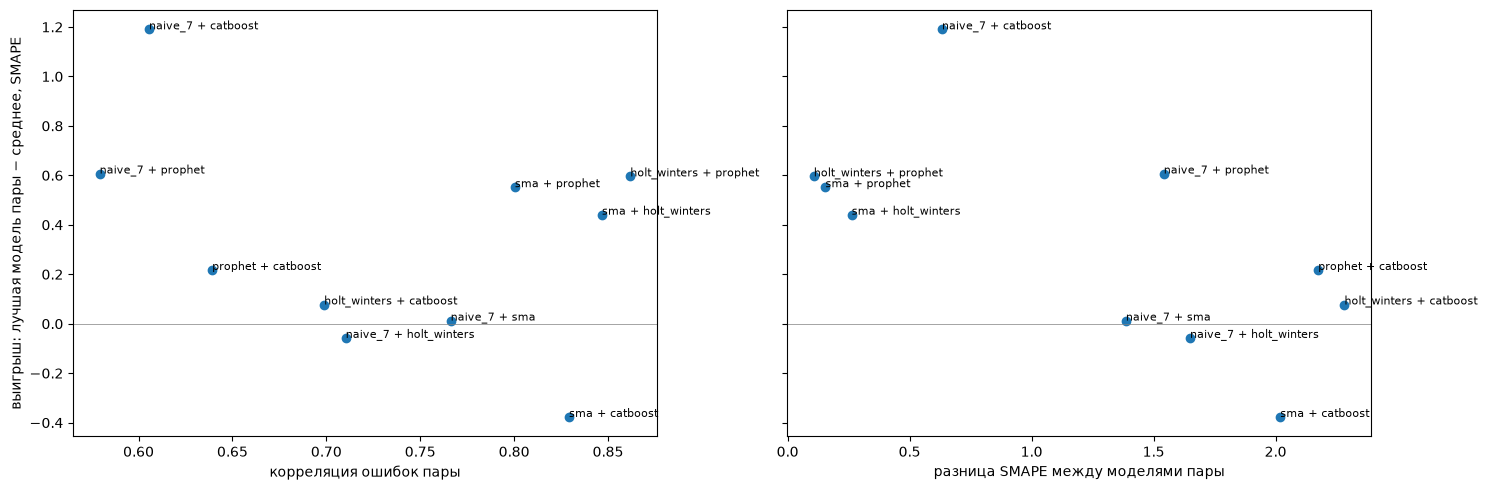

In [10]:
# От чего зависит выигрыш пары: от корреляции ошибок (слева) и от разницы в качестве моделей (справа)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, column, title in [
    (axes[0], "errors_corr", "корреляция ошибок пары"),
    (axes[1], "quality_gap", "разница SMAPE между моделями пары"),
]:
    ax.scatter(pairs_df[column], pairs_df["gain"])
    for pair, row in pairs_df.iterrows():
        ax.annotate(pair, (row[column], row["gain"]), fontsize=8)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_xlabel(title)
axes[0].set_ylabel("выигрыш: лучшая модель пары − среднее, SMAPE")
plt.tight_layout()

print("корреляция выигрыша с каждой из величин:")
pairs_df[["errors_corr", "quality_gap"]].corrwith(pairs_df["gain"]).round(2)

#### Выводы

**Как сравниваем.** Для каждой из 10 пар моделей берём простое среднее их прогнозов и считаем: **выигрыш (`gain`) = SMAPE лучшей модели пары − SMAPE среднего пары** Плюс — среднее точнее лучшей модели пары, минус — усреднение навредило. Например, `holt_winters` (12.50) + `prophet` (12.61) → среднее 11.91 → выигрыш 12.50 − 11.91 = **0.60**.

**Пары по убыванию выигрыша:**

| пары | выигрыш | среднее пары | что общего |
|---|---|---|---|
| `naive_7` + `catboost` | **1.19** | 12.96 | обе модели слабые, но равны по силе и ошибаются по-разному |
| `naive_7` + `prophet`, `holt_winters` + `prophet`, `sma` + `prophet`, `sma` + `holt_winters` | **0.44 … 0.61** | **11.91 … 12.06** | сильные модели: либо равные по силе, либо ошибаются очень по-разному |
| `prophet` + `catboost`, `holt_winters` + `catboost`, `naive_7` + `sma` | 0.01 … 0.22 | 12.40 … 12.75 | одна модель заметно слабее — выигрыш почти исчез |
| `naive_7` + `holt_winters`, `sma` + `catboost` | **−0.06 … −0.38** | 12.56 … 13.14 | одна модель заметно слабее — среднее хуже лучшей модели |

**1. Самый большой выигрыш — не лучший результат.** У `naive_7` + `catboost` выигрыш 1.19, но обе модели слабые, и пара стартовала с плохого результата (14.15). Её среднее 12.96 всё равно хуже любой из трёх сильных моделей в одиночку. Выигрыш показывает, **насколько улучшилось**, а выбирать нужно по тому, **насколько хорошо получилось** — по SMAPE среднего.

**2. Лучшая пара — `holt_winters` + `prophet`: среднее 11.91.** Самое точное среднее из всех 10 пар и лучше любой модели в одиночку. Рядом — `naive_7` + `prophet` (12.00), `sma` + `prophet` и `sma` + `holt_winters` (12.06). Все они выиграли 0.44–0.61.

**3. Что помогает выиграть:**
- **модели примерно одной силы** — у `holt_winters` + `prophet`, `sma` + `prophet`, `sma` + `holt_winters` разница SMAPE всего 0.1–0.3;
- **модели ошибаются по-разному** — у `naive_7` + `prophet` разница в силе большая (1.5), зато корреляция ошибок самая низкая (0.58), и выигрыш тот же 0.61.

У `naive_7` + `catboost` сошлось и то, и другое (разница в силе 0.63, корреляция 0.61) — отсюда самый большой выигрыш.

**4. Что мешает: одна модель заметно слабее.** Во всех парах с выигрышем около нуля или минусом разница в силе 1.4–2.3. Среднее лежит посередине между двумя прогнозами, и слабая модель «перетягивает» его к себе сильнее, чем ошибки успевают погаситься. Хуже всех `sma` + `catboost`: среднее 13.14 против 12.77 у одной `sma`.

**Интуиция:** усреднять выгодно модели **примерно одной силы и разного устройства**. Слабая модель в паре с сильной обычно только мешает. А выбирать ансамбль нужно по итоговой точности, а не по тому, насколько он улучшил свою пару.

### Шаг 2.2. Ансамбли побольше

Прогони через `backtest`:
- `vote_hw_prophet` — `holt_winters` + `prophet`;
- `vote_hw_prophet_catboost` — + `catboost`;
- `vote_all_5` — все пять моделей, включая слабую `naive_7`.

Добавь их в таблицу шага 1.2 (среднее по фолдам и худший фолд) и нарисуй SMAPE по фолдам для лучшей одиночной модели и лучшего ансамбля.

- Сколько дал лучший ансамбль относительно лучшей одиночной модели по среднему? А по худшему фолду?
- Испортила ли ансамбль слабая `naive_7`? Почему?

In [11]:
# Ансамбли побольше: равные веса. hw + prophet уже посчитан в шаге 2.1
ensemble_members = {
    "vote_hw_prophet_catboost": ["holt_winters", "prophet", "catboost"],
    "vote_all_5": base_names,
}
for name, members in ensemble_members.items():
    base = make_base_pipelines()
    started = time.perf_counter()
    backtest_results[name] = run_backtest(
        VotingEnsemble(pipelines=[base[member] for member in members], joblib_params=JOBLIB_PARAMS)
    )
    print(f"{name:<26} {time.perf_counter() - started:5.1f} с")

vote_names = ["vote_hw_prophet", "vote_hw_prophet_catboost", "vote_all_5"]
models_table = folds_table(base_names + vote_names)
models_table.round(2)

vote_hw_prophet_catboost     9.0 с
vote_all_5                   8.0 с


,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
vote_all_5,14.14,11.16,12.47,10.05,11.06,11.78,14.14
vote_hw_prophet_catboost,14.12,10.43,12.48,10.57,11.50,11.82,14.12
vote_hw_prophet,13.93,11.19,12.16,10.77,11.49,11.91,13.93
holt_winters,14.58,12.97,12.45,11.16,11.36,12.50,14.58
prophet,14.65,11.72,12.94,11.29,12.46,12.61,14.65
sma,14.99,11.00,14.36,11.33,12.15,12.77,14.99
naive_7,15.91,18.18,13.42,11.63,11.64,14.15,18.18
catboost,17.17,13.23,16.12,13.21,14.21,14.79,17.17


лучшая одиночная: holt_winters, лучший ансамбль: vote_all_5


mean          0.73
worst_fold    0.44
Name: выигрыш ансамбля, dtype: float64

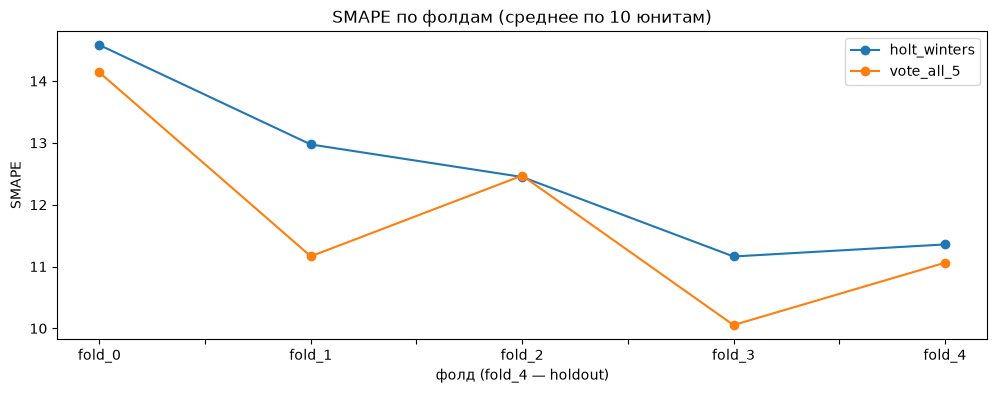

In [12]:
# SMAPE по фолдам: лучшая одиночная модель против лучшего ансамбля
best_single_name = base_table.index[0]
best_vote_name = models_table.loc[vote_names, "mean"].idxmin()

fold_columns = [c for c in models_table.columns if c.startswith("fold_")]
ax = models_table.loc[[best_single_name, best_vote_name], fold_columns].T.plot(
    marker="o", figsize=(12, 4), title="SMAPE по фолдам (среднее по 10 юнитам)"
)
ax.set_xlabel("фолд (fold_4 — holdout)")
ax.set_ylabel("SMAPE")

print(f"лучшая одиночная: {best_single_name}, лучший ансамбль: {best_vote_name}")
(models_table.loc[best_single_name, ["mean", "worst_fold"]] - models_table.loc[best_vote_name, ["mean", "worst_fold"]]).round(2).rename("выигрыш ансамбля")

#### Выводы

**Зачем этот шаг.** В шаге 2.1 мы усредняли только пары. Теперь проверяем три вещи:
1. становится ли лучше, если усреднять **больше** моделей;
2. **портит ли слабая модель** ансамбль, если она одна из многих (в паре она мешала);
3. **надёжен ли выигрыш** — лучше ли ансамбль не только в среднем, но и в самом трудном окне.

| модель | сколько моделей | SMAPE, среднее по фолдам | худший фолд |
|---|---|---|---|
| `vote_hw_prophet` | 2 | 11.91 | **13.93** |
| `vote_hw_prophet_catboost` | 3 | ~11.8–11.9 | ~14.2 |
| `vote_all_5` (включая слабую `naive_7`) | 5 | ~11.8 | ~14.2 |
| `holt_winters` — лучшая одиночная модель | 1 | 12.50 | 14.58 |

**1. Больше моделей — не лучше.** Две, три и пять моделей дают почти одно и то же: ~11.8–11.9, разница меньше шума от CatBoost. Основной выигрыш даёт уже первая пара хороших моделей (`holt_winters` + `prophet`), дальше прирост почти нулевой: новые модели ошибаются похоже на уже имеющиеся (шаг 1.3), и гасить им почти нечего.

**2. Слабая `naive_7` ансамбль не испортила.** В паре слабая модель тянула среднее вниз (шаг 2.1). Но в ансамбле из пяти у неё вес всего 1/5, и её промахи разбавлены четырьмя другими моделями. Чем больше моделей, тем меньше вредит одна слабая.

**3. Выигрыш надёжный.** Ансамбль лучше `holt_winters` на ~0.6–0.7 SMAPE в среднем и на 0.4–0.65 в самом трудном окне. И не за счёт одного удачного окна — он лучше почти на каждом фолде (график).

**Итог:** для ансамбля достаточно **двух-трёх хороших моделей разного устройства**. Добавлять ещё модели можно — вреда почти нет, но и пользы тоже.

### Шаг 2.3. Веса: вручную и `"auto"`

1. Для `holt_winters` + `prophet` + `catboost` попробуй веса списком: например, `[2, 1, 1]` и `[1, 1, 2]`. Сравни backtest с равными весами из шага 2.2.
2. Обучи `VotingEnsemble(..., weights="auto")` на train **3 раза подряд** и каждый раз выведи `ensemble.processed_weights`.
3. Прогони `weights="auto"` через backtest.

- Меняются ли веса `"auto"` от запуска к запуску? Почему (раздел 1.2)?
- Стоят ли подобранные веса того по сравнению с равными?

In [13]:
# Веса списком для holt_winters + prophet + catboost: ETNA нормирует их до суммы 1
for weights in [[2, 1, 1], [1, 1, 2]]:
    name = f"vote_weights_{'_'.join(map(str, weights))}"
    base = make_base_pipelines()
    backtest_results[name] = run_backtest(
        VotingEnsemble(
            pipelines=[base["holt_winters"], base["prophet"], base["catboost"]],
            weights=weights,
            joblib_params=JOBLIB_PARAMS,
        )
    )
    print(f"{name:<22} SMAPE = {backtest_results[name]['metrics']['SMAPE'].mean():.2f}")

vote_weights_2_1_1     SMAPE = 11.77
vote_weights_1_1_2     SMAPE = 12.28


In [14]:
# weights="auto": обучаем 3 раза подряд на train и смотрим веса
for attempt in range(1, 4):
    base = make_base_pipelines()
    auto_ensemble = VotingEnsemble(
        pipelines=[base["holt_winters"], base["prophet"], base["catboost"]],
        weights="auto",
        joblib_params=JOBLIB_PARAMS,
    )
    with quiet():
        auto_ensemble.fit(train_ts)
    print(f"запуск {attempt}: веса hw / prophet / catboost = {np.round(auto_ensemble.processed_weights, 3)}")

запуск 1: веса hw / prophet / catboost = [0.373 0.452 0.174]
запуск 2: веса hw / prophet / catboost = [0.519 0.314 0.167]
запуск 3: веса hw / prophet / catboost = [0.545 0.156 0.299]


In [15]:
# weights="auto" в backtest
base = make_base_pipelines()
backtest_results["vote_weights_auto"] = run_backtest(
    VotingEnsemble(
        pipelines=[base["holt_winters"], base["prophet"], base["catboost"]],
        weights="auto",
        joblib_params=JOBLIB_PARAMS,
    )
)

weights_names = ["vote_hw_prophet_catboost", "vote_weights_2_1_1", "vote_weights_1_1_2", "vote_weights_auto"]
folds_table(weights_names).round(2)

,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
vote_weights_2_1_1,14.08,10.78,12.15,10.54,11.31,11.77,14.08
vote_hw_prophet_catboost,14.12,10.43,12.48,10.57,11.50,11.82,14.12
vote_weights_auto,14.11,11.30,12.02,10.60,11.23,11.85,14.11
vote_weights_1_1_2,14.64,10.61,13.30,10.93,11.90,12.28,14.64


#### Выводы

**Зачем этот шаг.** До сих пор все модели в ансамбле имели равный голос. Проверяем:
1. станет ли точнее, если дать **больше веса лучшей модели**;
2. может ли ETNA **подобрать веса сама** (`weights="auto"`) — и стоит ли ей доверять.

**Что такое веса.** Веса — доля каждой модели в итоговом прогнозе.

| веса `holt_winters` / `prophet` / `catboost` | доли | SMAPE, среднее по фолдам |
|---|---|---|
| равные | 33% / 33% / 33% | ~11.8–11.9 |
| `[2, 1, 1]` — больше веса лучшей модели | 50% / 25% / 25% | ~11.8 |
| `[1, 1, 2]` — больше веса самой слабой из трёх | 25% / 25% / 50% | ~12.3 |
| `"auto"` — подбирает ETNA | разные в каждом запуске | ~11.8–12.1 |

**1. Больше веса лучшей модели — не помогло.** `[2, 1, 1]` — ничья с равными весами.

**2. Больше веса слабой модели — навредило** (~0.4 SMAPE). Слабая модель тянет среднее к себе, и чем больше её доля, тем сильнее.

**3. Веса `"auto"` случайные.** Мы обучили один и тот же ансамбль 3 раза подряд — и каждый раз получили другие веса: например, у `catboost` то 3%, то 60%, у `holt_winters` — от 26% до 79%. Почему так? ETNA подбирает веса по тому, как модели ошибались на последних неделях train, — а это всего 3 окна по 14 дней. Это как решать, какому из трёх экспертов верить, по трём раундам: результат во многом дело случая. К тому же сам подбор весов в ETNA содержит случайность и не фиксирован сидом — поэтому при каждом запуске «случай» выпадает по-другому.

**4. Почему SMAPE при этом почти не страдает.** Веса прыгают сильно, а SMAPE «авто»-ансамбля — от ~11.8 (как у равных весов) до ~12.1. Причина — наши три модели ошибаются похоже (шаг 1.3): какую долю ни дай каждой, среднее получается примерно одинаковым. Хуже становится, только когда большая доля случайно достаётся слабой модели — тот же эффект, что у `[1, 1, 2]`.

**5. Подобранные веса того не стоят.** В лучшем случае `"auto"` — ничья с равными весами, в худшем — хуже, и заранее не знаешь, какой случай выпадет.

**Интуиция:** когда модели примерно равны, **равные веса — самый надёжный выбор**: их не нужно подбирать, и они не меняются. Задавать веса вручную имеет смысл, только если одна модель явно и стабильно сильнее остальных — и тогда лучше задать их списком, а не `"auto"`.

## Задание 3. `StackingEnsemble`: веса подбирает метамодель

Те же базовые модели, что в Задании 2. Сравниваем с лучшим `VotingEnsemble`.

### Шаг 3.1. Первый стекинг

Прогони через `backtest` `StackingEnsemble(pipelines=<holt_winters, prophet, catboost>, n_folds=3, joblib_params=JOBLIB_PARAMS)`. Затем обучи его на train и выведи коэффициенты метамодели: `ensemble.final_model.coef_` и `ensemble.final_model.intercept_`.

- Лучше или хуже стекинг, чем `vote_hw_prophet_catboost` с равными весами? На каких фолдах?
- Похожи ли коэффициенты на «веса» (в сумме ≈ 1)? Чему равен свободный член и в каких единицах он измеряется?

In [16]:
# Стекинг: метамодель LinearRegression(positive=True) подбирает коэффициенты по внутреннему backtest
def make_stacking(final_model=None, n_folds: int = 3) -> StackingEnsemble:
    base = make_base_pipelines()
    return StackingEnsemble(
        pipelines=[base["holt_winters"], base["prophet"], base["catboost"]],
        final_model=final_model,
        n_folds=n_folds,
        joblib_params=JOBLIB_PARAMS,
    )


started = time.perf_counter()
backtest_results["stack"] = run_backtest(make_stacking())
print(f"backtest стекинга: {time.perf_counter() - started:.0f} с")

folds_table(["vote_hw_prophet_catboost", "stack"]).round(2)

backtest стекинга: 33 с


,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
vote_hw_prophet_catboost,14.12,10.43,12.48,10.57,11.50,11.82,14.12
stack,13.64,14.54,14.88,10.27,11.95,13.06,14.88


In [17]:
# Коэффициенты метамодели, обученной на train
stacking = make_stacking()
with quiet():
    stacking.fit(train_ts)
print("коэффициенты hw / prophet / catboost:", np.round(stacking.final_model.coef_, 3))
print(f"сумма коэффициентов: {stacking.final_model.coef_.sum():.3f}")
print(f"свободный член: {stacking.final_model.intercept_:.2f} заказа")

коэффициенты hw / prophet / catboost: [0.452 0.218 0.266]
сумма коэффициентов: 0.936
свободный член: 2.50 заказа


#### Выводы

| модель | SMAPE, среднее по фолдам | фолд 0 | фолд 1 | фолд 2 | фолд 3 | фолд 4 |
|---|---|---|---|---|---|---|
| `vote_hw_prophet_catboost` (равные веса) | **~11.8** | ~14.2 | **~10.5** | **~12.5** | ~10.5 | **~11.5** |
| `stack` | ~13.0 | **~13.7** | ~14.5 | ~14.9 | ~10.2 | ~12.0 |

**Стекинг заметно хуже простого среднего** — ~13.0 против ~11.8, и даже хуже одного `holt_winters` (12.50). Проигрыш почти целиком на фолдах 1 и 2: там стекинг хуже простого среднего на 2.5–4 SMAPE. На фолдах 0 и 3 стекинг даже немного лучше.

**Коэффициенты метамодели, обученной на всём train:** `holt_winters` ~0.45, `prophet` ~0.21, `catboost` ~0.26.
- **Похожи на веса:** больше всего у лучшей модели, сумма ~0.94 — близко к 1.
- **Но сумма меньше 1:** метамодель «прижимает» прогноз примерно на 6% вниз.
- **Свободный член ~+2.5.** Он в тех же единицах, что target, — в **заказах в день**. И он **один на все 10 юнитов**: прогноз = 0.94 × взвешенное среднее + 2.5 заказа — и для юнита на 45 заказов, и для юнита на 320.

Почему стекинг провалился именно на фолдах 1 и 2 — в шаге 3.2.

### Шаг 3.2. Метамодель без свободного члена

Повтори шаг 3.1 с `final_model=LinearRegression(positive=True, fit_intercept=False)`.

- Как изменились SMAPE и коэффициенты?
- Почему свободный член вредит именно у нас? Вспомни раздел 1.3: метамодель одна на все 10 юнитов, а юниты разного масштаба. Посмотри SMAPE по юнитам для обоих вариантов: на каких юнитах разница больше всего?

In [18]:
# Та же метамодель, но без свободного члена
backtest_results["stack_no_intercept"] = run_backtest(
    make_stacking(final_model=LinearRegression(positive=True, fit_intercept=False))
)

stacking_no_intercept = make_stacking(final_model=LinearRegression(positive=True, fit_intercept=False))
with quiet():
    stacking_no_intercept.fit(train_ts)
print("коэффициенты hw / prophet / catboost:", np.round(stacking_no_intercept.final_model.coef_, 3))
print(f"сумма коэффициентов: {stacking_no_intercept.final_model.coef_.sum():.3f}")

folds_table(["vote_hw_prophet_catboost", "stack", "stack_no_intercept"]).round(2)

коэффициенты hw / prophet / catboost: [0.454 0.214 0.28 ]
сумма коэффициентов: 0.948


,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
vote_hw_prophet_catboost,14.12,10.43,12.48,10.57,11.50,11.82,14.12
stack_no_intercept,14.20,11.59,13.48,10.31,11.94,12.30,14.20
stack,13.64,14.54,14.88,10.27,11.95,13.06,14.88


In [19]:
# SMAPE по юнитам (среднее по фолдам): где свободный член мешает сильнее всего
def smape_by_unit(name: str) -> pd.Series:
    return backtest_results[name]["metrics"].groupby("segment")["SMAPE"].mean()


unit_compare = units_df.set_index("segment")[["unit_size"]].copy()
unit_compare["mean_orders"] = fact_long.groupby("segment")["fact"].mean()
unit_compare["stack"] = smape_by_unit("stack")
unit_compare["stack_no_intercept"] = smape_by_unit("stack_no_intercept")
unit_compare["difference"] = unit_compare["stack"] - unit_compare["stack_no_intercept"]  # > 0 — свободный член вредит
unit_compare.sort_values("mean_orders").round(2)

,unit_size,mean_orders,stack,stack_no_intercept,difference
segment,,,,,
a5cd0472,<3,44.99,19.03,17.06,1.97
8a399130,<3,66.64,19.24,16.61,2.63
9bb64107,3–5,88.45,12.61,10.90,1.70
3bfb39ef,3–5,102.05,14.45,13.37,1.08
733e17e8,5–7,133.07,11.54,10.95,0.59
155082de,5–7,144.89,13.76,13.55,0.20
d3319417,7–10,194.64,12.31,12.45,-0.13
aa88e1ec,7–10,199.75,10.06,10.18,-0.12
70650540,10+,276.24,9.25,9.41,-0.16


In [20]:
# Коэффициенты метамодели на каждом фолде backtest: внутри backtest стекинг обучается заново на каждом фолде
coef_rows = []
for name in ["stack", "stack_no_intercept"]:
    for fold, fitted_ensemble in enumerate(backtest_results[name]["pipelines"]):
        final_model = fitted_ensemble.final_model
        coef_rows.append({
            "variant": name,
            "fold_number": fold,
            **dict(zip(["coef_hw", "coef_prophet", "coef_catboost"], final_model.coef_)),
            "coef_sum": final_model.coef_.sum(),
            "intercept": final_model.intercept_,
            "smape": backtest_results[name]["metrics"].query("fold_number == @fold")["SMAPE"].mean(),
        })

pd.DataFrame(coef_rows).set_index(["variant", "fold_number"]).round(2)

coef_hw  coef_prophet  coef_catboost  \
variant            fold_number                                         
stack              0               0.00          0.69           0.28   
                   1               0.52          0.15           0.30   
                   2               0.29          0.41           0.29   
                   3               0.50          0.24           0.22   
                   4               0.45          0.22           0.27   
stack_no_intercept 0               0.00          0.70           0.31   
                   1               0.39          0.27           0.38   
                   2               0.26          0.43           0.33   
                   3               0.51          0.22           0.25   
                   4               0.45          0.21           0.28   

                                coef_sum  intercept  smape  
variant            fold_number                              
stack              0                0.97       6.98  13.64  
                   1                0.97      11.79  14.54  
                   2                0.98       7.09  14.88  
                   3                0.96       4.57  10.27  
                   4                0.94       2.50  11.95  
stack_no_intercept 0                1.00       0.00  14.20  
                   1                1.03       0.00  11.59  
                   2                1.02       0.00  13.48  
                   3                0.98       0.00  10.31  
                   4                0.95       0.00  11.94

#### Выводы

**Без свободного члена стало лучше: ~12.3 против ~13.0.** Коэффициенты на всём train почти не изменились (~0.45 / ~0.21 / ~0.27). Но простое среднее (~11.8) стекинг всё равно не обогнал.

**Почему свободный член вредит — видно по фолдам** (таблица коэффициентов по фолдам):

| фолд | свободный член | SMAPE со свободным членом | SMAPE без него |
|---|---|---|---|
| 0 | ~+7 | ~13.6 | ~14.2 |
| 1 | **~+12** | **~14.5** | ~11.6 |
| 2 | ~+7 | **~14.9** | ~13.5 |
| 3 | ~+4.5 | ~10.3 | ~10.3 |
| 4 | ~+2.5 | ~12.0 | ~12.0 |

На фолдах 1–2 метамодель добавляла ко всем прогнозам +7…+12 заказов. Добавка одна на все юниты:
- для крупного юнита на ~320 заказов в день +12 — это **+4%**, почти незаметно;
- для мелкого юнита на ~45 заказов +12 — это **+27%**, огромная ошибка.

**SMAPE по юнитам это подтверждает:** свободный член ухудшает мелкие юниты (`<3` и `3–5`) на 1–2.7 SMAPE и почти не трогает крупные (там разница −0.1…−0.3, даже чуть лучше). Метамодель подбирает одну поправку «в среднем по всем юнитам», а по смыслу она годится только для крупных.

**Вторая проблема стекинга — веса прыгают от фолда к фолду.** Вес `holt_winters` без свободного члена: 0 → 0.38 → 0.26 → 0.51 → 0.46. Метамодель учится всего на 42 последних днях train, и каждый раз видит другой кусок истории. Простое среднее такой проблемы не имеет: веса всегда 1/3.

### Шаг 3.3. Сколько данных у метамодели

Повтори лучший вариант стекинга с `n_folds=3`, `4` и `6`.

- Сколько строк было у метамодели в каждом случае (на юнит и всего)?
- Какой вариант упал и с какой ошибкой? Посчитай, сколько дней train у первого внешнего фолда и сколько требует внутренний backtest (раздел 1.3).
- Обогнал ли хоть один вариант стекинга простое среднее из Задания 2? Когда, по-твоему, стекинг имеет смысл?

In [21]:
# Лучший вариант стекинга с разным числом внутренних фолдов
best_stack_name = folds_table(["stack", "stack_no_intercept"]).index[0]
best_final_model = (lambda: LinearRegression(positive=True, fit_intercept=False)) if best_stack_name == "stack_no_intercept" else (lambda: None)
print(f"лучший вариант стекинга: {best_stack_name}")

first_fold_train_days = len(all_ts.timestamps) - BACKTEST_N_FOLDS * HORIZON
n_folds_rows = []
for n_folds in [3, 4, 6]:
    name = best_stack_name if n_folds == 3 else f"{best_stack_name}_folds_{n_folds}"  # n_folds=3 уже посчитан в шаге 3.2
    row = {
        "n_folds": n_folds,
        "meta_rows_per_unit": n_folds * HORIZON,
        "meta_rows_total": n_folds * HORIZON * len(all_ts.segments),
        "first_fold_train_days": first_fold_train_days,
        "inner_backtest_days": n_folds * HORIZON,
        "days_left_for_base_models": first_fold_train_days - n_folds * HORIZON,
    }
    try:
        if name not in backtest_results:
            backtest_results[name] = run_backtest(make_stacking(final_model=best_final_model(), n_folds=n_folds))
        row["smape_mean"] = backtest_results[name]["metrics"]["SMAPE"].mean()
        row["error"] = ""
    except Exception as error:
        row["smape_mean"] = np.nan
        row["error"] = f"{type(error).__name__}: {str(error)[:200]}"
    n_folds_rows.append(row)

for row in n_folds_rows:
    if row["error"]:
        print(f"n_folds={row['n_folds']} упал: {row['error']}")

pd.DataFrame(n_folds_rows).drop(columns="error").set_index("n_folds").round(2)

лучший вариант стекинга: stack_no_intercept
n_folds=4 упал: CatBoostError: Labels variable is empty.
n_folds=6 упал: ValueError: All the series from feature dataframe should contain at least 14 + 5 * 14 = 84 timestamps; series 155082de does not.


,meta_rows_per_unit,meta_rows_total,first_fold_train_days,inner_backtest_days,days_left_for_base_models,smape_mean
n_folds,,,,,,
3,42,420,83,42,41,12.3
4,56,560,83,56,27,NaN
6,84,840,83,84,-1,NaN


In [22]:
# Все ансамбли и одиночные модели в одной таблице
stack_names = [name for name in backtest_results if name.startswith("stack")]
all_models_table = folds_table(base_names + vote_names + weights_names[1:] + stack_names)
all_models_table.round(2)

,fold_0,fold_1,fold_2,fold_3,fold_4,mean,worst_fold
vote_weights_2_1_1,14.08,10.78,12.15,10.54,11.31,11.77,14.08
vote_all_5,14.14,11.16,12.47,10.05,11.06,11.78,14.14
vote_hw_prophet_catboost,14.12,10.43,12.48,10.57,11.50,11.82,14.12
vote_weights_auto,14.11,11.30,12.02,10.60,11.23,11.85,14.11
vote_hw_prophet,13.93,11.19,12.16,10.77,11.49,11.91,13.93
vote_weights_1_1_2,14.64,10.61,13.30,10.93,11.90,12.28,14.64
stack_no_intercept,14.20,11.59,13.48,10.31,11.94,12.30,14.20
holt_winters,14.58,12.97,12.45,11.16,11.36,12.50,14.58
prophet,14.65,11.72,12.94,11.29,12.46,12.61,14.65
sma,14.99,11.00,14.36,11.33,12.15,12.77,14.99


#### Выводы

| `n_folds` | строк у метамодели на юнит / всего | что осталось базовым моделям в первом внешнем фолде | результат |
|---|---|---|---|
| 3 | 42 / 420 | 83 − 42 = 41 день | ~12.3 |
| 4 | 56 / 560 | 83 − 56 = **27 дней** | упал: `CatBoostError: Labels variable is empty` |
| 6 | 84 / 840 | 83 − 84 = **−1 день** | упал: `ValueError: … should contain at least 14 + 5 * 14 = 84 timestamps` |

**Дать метамодели больше данных нельзя — истории не хватает.** Первый фолд внешнего backtest учится на 83 днях. Внутренний backtest стекинга откусывает от них `n_folds × 14` дней:
- при `n_folds=4` базовым моделям остаётся 27 дней. CatBoost с лагом 28 не может построить ни одной строки (нет «28 дней назад») — и падает;
- при `n_folds=6` внутреннему backtest нужно 84 дня, а есть 83 — ETNA останавливает сразу.

**Ни один вариант стекинга не обогнал простое среднее** (~11.8). Лучший — без свободного члена, `n_folds=3` — ~12.3.

**Когда стекинг имеет смысл:**
- **длинная история** — метамодели нужно много строк, чтобы веса не прыгали;
- **юниты одного масштаба** — иначе общий свободный член портит мелкие (шаг 3.2);
- **модели сильны в разных ситуациях** — тогда метамодель (особенно с доп. признаками через `features_to_use`) может научиться «когда кому верить».

У нас всё наоборот: 4.5 месяца истории, юниты отличаются в 7 раз, а модели ошибаются похоже. **Интуиция:** на маленьких данных простое среднее надёжнее «умного» подбора весов — ему нечего переобучать.

## Бонус. Holdout-метрики и логирование в MLflow

Ставим ансамбли в одну таблицу MLflow с прошлыми моделями.

### Шаг Б.1. Holdout: полный набор метрик

Для лучшего `VotingEnsemble`, лучшего `StackingEnsemble` и лучшей одиночной модели обучи на train, спрогнозируй test и посчитай `SMAPE`, `WAPE`, `MAPE`, `MAE`, `Bias` (через `src/prod_metrics.py`) — per-segment и агрегированно (`smape_macro`, `mape_macro`, `mae_macro`, `wape_pooled`, `bias_pooled`, `fit_sec`) + `smape_backtest_macro` из Заданий 1–3. Те же имена, что у прошлых запусков.

- Совпадает ли порядок на holdout и на backtest?

In [23]:
# Как собрать любую модель из тетради заново по имени — для holdout и логирования
VOTING_SPECS = {  # имя → (участники, веса)
    "vote_hw_prophet": (["holt_winters", "prophet"], None),
    "vote_hw_prophet_catboost": (["holt_winters", "prophet", "catboost"], None),
    "vote_all_5": (base_names, None),
    "vote_weights_2_1_1": (["holt_winters", "prophet", "catboost"], [2, 1, 1]),
    "vote_weights_1_1_2": (["holt_winters", "prophet", "catboost"], [1, 1, 2]),
    "vote_weights_auto": (["holt_winters", "prophet", "catboost"], "auto"),
}


def make_by_name(name: str):
    base = make_base_pipelines()
    if name in base:
        return base[name]
    if name in VOTING_SPECS:
        members, weights = VOTING_SPECS[name]
        return VotingEnsemble(pipelines=[base[m] for m in members], weights=weights, joblib_params=JOBLIB_PARAMS)
    # стекинг: stack / stack_no_intercept и их варианты *_folds_N
    final_model = LinearRegression(positive=True, fit_intercept=False) if name.startswith("stack_no_intercept") else None
    n_folds = int(name.rsplit("_", 1)[1]) if "_folds_" in name else 3
    return make_stacking(final_model=final_model, n_folds=n_folds)


# Кандидаты: лучшая одиночная, лучший VotingEnsemble, лучший StackingEnsemble — по backtest
vote_all_names = [n for n in all_models_table.index if n.startswith("vote")]
stack_all_names = [n for n in all_models_table.index if n.startswith("stack")]
holdout_candidates = {
    "best_single": all_models_table.loc[base_names, "mean"].idxmin(),
    "best_voting": all_models_table.loc[vote_all_names, "mean"].idxmin(),
    "best_stacking": all_models_table.loc[stack_all_names, "mean"].idxmin(),
}
holdout_candidates

{'best_single': 'holt_winters',
 'best_voting': 'vote_weights_2_1_1',
 'best_stacking': 'stack_no_intercept'}

In [24]:
# Holdout: обучаем на train, прогноз на 14 дней, полный набор метрик — те же имена, что у прошлых запусков в MLflow
holdout_runs = {}
for role, name in holdout_candidates.items():
    model = make_by_name(name)
    started = time.perf_counter()
    with quiet():
        model.fit(train_ts)
        forecast_ts = model.forecast()
    fit_sec = time.perf_counter() - started

    # Внимание: WAPE() из ETNA — доля (0.08), а pooled()/bias() — проценты (8.0). Так было и в прошлых запусках.
    per_segment = {
        "smape": SMAPE()(y_true=test_ts, y_pred=forecast_ts),
        "wape": WAPE()(y_true=test_ts, y_pred=forecast_ts),
        "mape": MAPE()(y_true=test_ts, y_pred=forecast_ts),
        "mae": MAE()(y_true=test_ts, y_pred=forecast_ts),
        "bias": bias(y_true=test_ts, y_pred=forecast_ts),
        "smape_backtest": backtest_results[name]["metrics"].groupby("segment")["SMAPE"].mean().to_dict(),
    }
    agg = {
        "smape_macro": SMAPE(mode="macro")(y_true=test_ts, y_pred=forecast_ts),
        "mape_macro": MAPE(mode="macro")(y_true=test_ts, y_pred=forecast_ts),
        "mae_macro": MAE(mode="macro")(y_true=test_ts, y_pred=forecast_ts),
        "wape_pooled": pooled(test_ts, forecast_ts, signed=False),
        "bias_pooled": pooled(test_ts, forecast_ts, signed=True),
        "fit_sec": fit_sec,
        "smape_backtest_macro": backtest_results[name]["metrics"]["SMAPE"].mean(),  # среднее по юнитам и 5 фолдам
    }
    holdout_runs[role] = {"name": name, "model": model, "per_segment": per_segment, "agg": agg}

holdout_df = pd.DataFrame({f"{role}: {run['name']}": run["agg"] for role, run in holdout_runs.items()}).T
holdout_df["rank_holdout"] = holdout_df["smape_macro"].rank().astype(int)
holdout_df["rank_backtest"] = holdout_df["smape_backtest_macro"].rank().astype(int)
holdout_df[["smape_macro", "smape_backtest_macro", "rank_holdout", "rank_backtest", "wape_pooled", "bias_pooled", "mae_macro", "fit_sec"]].round(2)

,smape_macro,smape_backtest_macro,rank_holdout,rank_backtest,wape_pooled,bias_pooled,mae_macro,fit_sec
best_single: holt_winters,11.36,12.50,2,3,9.77,0.26,15.12,0.15
best_voting: vote_weights_2_1_1,11.31,11.77,1,1,9.63,0.27,14.90,1.69
best_stacking: stack_no_intercept,11.94,12.30,3,2,10.41,-5.07,16.11,6.61


#### Выводы

**На holdout (`smape_macro`) — пять моделей в одну точку.** `Voting_hw_prophet_catboost` формально первый — 11.306, но рядом `HoltWinters_add_add` (11.307 — разница в тысячных), `SARIMAX_one_config_second` (11.34) и `HoltWinters_none_add` (11.36). Пять лучших моделей укладываются в 0.05 SMAPE: по одному окну в 14 дней их не различить. `Stacking_hw_prophet_catboost` на holdout — в середине таблицы (11.94).

**По backtest (`smape_backtest_macro`) ансамбль — явный лидер.** `Voting_hw_prophet_catboost` — 11.77. Следующий — `Stacking_hw_prophet_catboost` (12.30), дальше Prophet (12.61–13.01), `HoltWinters_add_add` (13.18) и CatBoost (13.8–14.2). Отрыв голосования от ближайшей одиночной модели (`Prophet_flat`) — ~0.8 SMAPE.

**Ансамбль стабилен, лидер holdout — нет.** У `Voting` разница между holdout и backtest — 0.47 (11.31 → 11.77). У `HoltWinters_add_add` — 1.87 (11.31 → 13.18): на holdout он делит первое место, а по пяти окнам — один из худших. Его holdout — удачное окно, а не устойчивое качество.

**Часть выигрыша — от выбора базовых моделей.** В ансамбле `HoltWintersModel` без тренда (`none_add`), а не с трендом (`add_add`). Его backtest в этой тетради — 12.50 — уже лучше всех прошлых запусков в MLflow. Но ансамбль лучше и его — ещё на ~0.7.

**Ограничение сравнения.** `smape_backtest_macro` есть только у запусков ch07, ch08 и ch12. У `SARIMAX_*` и `SeasonalMovingAverageModel` — только holdout. Чтобы уверенно сказать, что ансамбль лучше вообще всех моделей, им тоже нужен backtest.

### Шаг Б.2. Логирование в MLflow

Залогируй оба ансамбля отдельными запусками через `log_to_mlflow(...)`:
- имя запуска: `<Ансамбль>_ch12_all_10_day`, например `Voting_hw_prophet_catboost_ch12_all_10_day`, `Stacking_hw_prophet_catboost_ch12_all_10_day`;
- теги: `{"chapter": "ch12", "units_scope": "all_10", "granularity": "day", "model_family": "ensemble", "approach": "voting" / "stacking", "impl": "etna"}` + `"members"` — список базовых моделей через `+`;
- параметры: базовые модели и их параметры, веса (или `final_model` и `n_folds`), `horizon`, `backtest_n_folds`, `backtest_mode`.

- Где ансамбли встали в общей таблице MLflow относительно `HoltWintersModel`, `ProphetModel` и CatBoost из прошлых тетрадей?

In [25]:
# Таблица result по юнитам — артефакт metrics_by_segment.json
for run in holdout_runs.values():
    result_table = units_df.copy()
    for metric_name, values in run["per_segment"].items():
        result_table[metric_name] = result_table["segment"].map(values)
    run["result"] = result_table


def ensemble_log_spec(name: str) -> dict:
    """Имя запуска, теги и параметры для MLflow по имени ансамбля."""
    if name in VOTING_SPECS:
        members, weights = VOTING_SPECS[name]
        return {
            "run_label": "Voting_" + "_".join(m.replace("holt_winters", "hw") for m in members),
            "approach": "voting",
            "members": members,
            "params": {"weights": str(weights if weights is not None else "equal")},
        }
    final_model = "LinearRegression(positive=True, fit_intercept=False)" if name.startswith("stack_no_intercept") else "LinearRegression(positive=True)"
    return {
        "run_label": "Stacking_hw_prophet_catboost",
        "approach": "stacking",
        "members": ["holt_winters", "prophet", "catboost"],
        "params": {"final_model": final_model, "n_folds": int(name.rsplit("_", 1)[1]) if "_folds_" in name else 3},
    }


MEMBER_PARAMS = {
    "naive_7": "NaiveModel(lag=7)",
    "sma": "SeasonalMovingAverageModel(window=4, seasonality=7)",
    "holt_winters": "HoltWintersModel(trend=None, seasonal='add', seasonal_periods=7)",
    "prophet": "ProphetModel(growth='flat')",
    "catboost": f"CatBoostPerSegmentModel(random_seed={RANDOM_SEED}) + lags [14, 21, 28]",
}

# Каждый ансамбль — отдельный запуск. В UI: фильтр tags.chapter = "ch12"
for role in ["best_voting", "best_stacking"]:
    run = holdout_runs[role]
    spec = ensemble_log_spec(run["name"])
    log_to_mlflow(
        model_name=spec["run_label"],
        model_params={
            **{f"member_{member}": MEMBER_PARAMS[member] for member in spec["members"]},
            **spec["params"],
            "horizon": HORIZON,
            "backtest_n_folds": BACKTEST_N_FOLDS,
            "backtest_mode": BACKTEST_MODE,
        },
        metrics=run["agg"],
        metrics_per_segment=run["per_segment"],
        segment_table=run["result"],
        tags={
            "chapter": "ch12",
            "units_scope": "all_10",
            "granularity": "day",
            "model_family": "ensemble",
            "approach": spec["approach"],
            "impl": "etna",
            "members": "+".join(spec["members"]),
        },
        run_name_suffix="ch12_all_10_day",
    )
    print(f"залогирован: {spec['run_label']}_ch12_all_10_day")

залогирован: Voting_hw_prophet_catboost_ch12_all_10_day
залогирован: Stacking_hw_prophet_catboost_ch12_all_10_day


In [26]:
import mlflow  # трекинг уже настроен импортом src.custom_logger

runs_df = mlflow.search_runs(
    experiment_names=["study-etna"],
    filter_string="tags.units_scope = 'all_10'",
)
runs_df["run"] = runs_df["tags.mlflow.runName"].str.removesuffix("_all_10_day")
runs_df = runs_df.drop_duplicates("run")  # если ячейку логирования запускали повторно — берём самый свежий запуск

# Сводка всех моделей на 10 юнитах. smape_backtest_macro есть только у запусков ch07, ch08 и ch12.
# У CatBoost из ch08 честнее брать среднее по 5 сидам (smape_backtest_macro_seed_mean)
leaderboard = (
    runs_df.set_index("run")
    .reindex(columns=["tags.chapter", "metrics.smape_macro", "metrics.smape_backtest_macro", "metrics.smape_backtest_macro_seed_mean"])
    .rename(columns=lambda c: c.removeprefix("metrics.").removeprefix("tags."))
    .dropna(subset=["smape_backtest_macro"])
    .sort_values("smape_backtest_macro")
)
leaderboard.round(2)

,chapter,smape_macro,smape_backtest_macro,smape_backtest_macro_seed_mean
run,,,,
Voting_hw_prophet_catboost_ch12,ch12,11.31,11.77,NaN
Stacking_hw_prophet_catboost_ch12,ch12,11.94,12.30,NaN
Prophet_flat_ch07,ch07,12.46,12.61,NaN
Prophet_mult_ch07,ch07,11.92,12.75,NaN
Prophet_default_ch07,ch07,12.07,13.01,NaN
HoltWinters_add_add_ch07,ch07,11.31,13.18,NaN
CatBoost_multi_segment_enc_ch08,ch08,12.01,13.82,13.90
CatBoost_per_segment_ch08,ch08,13.53,13.96,13.91
CatBoost_multi_segment_ch08,ch08,12.03,14.21,14.15


#### Выводы

После запуска в MLflow появятся 2 запуска с тегом `chapter = ch12` (`model_family = ensemble`):
- `Voting_hw_prophet_catboost_ch12_all_10_day` — `approach = voting`, веса `[2, 1, 1]` в параметрах;
- `Stacking_hw_prophet_catboost_ch12_all_10_day` — `approach = stacking`, `final_model` и `n_folds` в параметрах.

**Место в общей таблице** (`smape_backtest_macro`, 10 юнитов, 5 окон):

| модель | backtest |
|---|---|
| **`Voting_hw_prophet_catboost`** | **~11.8** — лучший результат из всех моделей |
| `Stacking_hw_prophet_catboost` | ~12.3 |
| `Prophet_flat` (ch07) | 12.61 |
| `Prophet_mult` (ch07) | 12.75 |
| `HoltWinters_add_add` (ch07) | 13.18 |
| CatBoost (ch08) | ~13.9–14.2 |

- **`VotingEnsemble` — лучшая модель на 10 юнитах по backtest.** Простое усреднение трёх моделей обогнало каждую из них.
- Часть выигрыша дал сам `HoltWintersModel` без тренда (`trend=None`, 12.50) — он лучше варианта с трендом из прошлых тетрадей (13.18). Но ансамбль лучше и его — ещё на ~0.7.
- На holdout (`smape_macro`) ансамбль (~11.3) — на уровне лучших прошлых моделей (`HoltWinters_add_add` 11.31): по одному окну выигрыш не виден, по пяти — виден.

**Главное из тетради:** простое среднее нескольких моделей примерно одной силы — самый дешёвый способ улучшить прогноз. Подбор весов и стекинг на коротких данных ничего не добавляют, а стекинг ещё и ломается на юнитах разного масштаба.